# Task 4 - Advanced Analytics & Statistical Modeling

## ApexPlanet Data Analytics Internship

### Objectives
- Statistical Analysis
- Hypothesis Testing
- Customer Segmentation (K-Means)
- Predictive Modeling
- Business Insights

**Author:** Ajay Kumar Giri

In [2]:
# ==========================================
# Task 4 - Import Required Libraries
# ==========================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

print("All Libraries Imported Successfully")

All Libraries Imported Successfully


In [3]:
# ==========================================
# Load Dataset
# ==========================================

dataset_path = "../data/cleaned/ecommerce_dataset_cleaned.csv"

df = pd.read_csv(dataset_path)

print("Dataset Loaded Successfully")

Dataset Loaded Successfully


In [4]:
# ==========================================
# Basic Dataset Information
# ==========================================

print("="*50)
print("Dataset Shape")
print("="*50)

print(df.shape)

print("\n")

print("="*50)
print("Column Names")
print("="*50)

print(df.columns.tolist())

print("\n")

print("="*50)
print("First Five Rows")
print("="*50)

display(df.head())

Dataset Shape
(1000, 7)


Column Names
['product_id', 'product_name', 'category', 'price', 'units_sold', 'rating', 'in_stock']


First Five Rows


,product_id,product_name,category,price,units_sold,rating,in_stock
0,1,Camera,Electronics,391.46,8,4.5,True
1,2,Shoes,Fashion,1091.88,333,3.0,True
2,3,Backpack,Fashion,893.51,200,3.8,True
3,4,Watch,Fashion,162.30,87,5.0,True
4,5,Camera,Electronics,1378.94,43,1.5,True


In [5]:
# ==========================================
# Dataset Information
# ==========================================

print("=" * 50)
print("Dataset Information")
print("=" * 50)

df.info()

print("\n")

print("=" * 50)
print("Missing Values")
print("=" * 50)

print(df.isnull().sum())

print("\n")

print("=" * 50)
print("Duplicate Rows")
print("=" * 50)

print(df.duplicated().sum())

Dataset Information
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   product_id    1000 non-null   int64  
 1   product_name  1000 non-null   str    
 2   category      1000 non-null   str    
 3   price         1000 non-null   float64
 4   units_sold    1000 non-null   int64  
 5   rating        1000 non-null   float64
 6   in_stock      1000 non-null   bool   
dtypes: bool(1), float64(2), int64(2), str(2)
memory usage: 48.0 KB


Missing Values
product_id      0
product_name    0
category        0
price           0
units_sold      0
rating          0
in_stock        0
dtype: int64


Duplicate Rows
0


In [6]:
# ==========================================
# Data Types
# ==========================================

display(df.dtypes)

product_id        int64
product_name        str
category            str
price           float64
units_sold        int64
rating          float64
in_stock           bool
dtype: object

## Descriptive Statistics

In [7]:
# ==========================================
# Descriptive Statistics
# ==========================================

numerical_columns = [
    "price",
    "units_sold",
    "rating"
]

statistics = df[numerical_columns].describe()

display(statistics)

,price,units_sold,rating
count,1000.000000,1000.000000,1000.000000
mean,759.020930,250.512000,2.982400
std,423.372666,142.866514,1.155346
min,10.350000,1.000000,1.000000
25%,388.665000,127.000000,2.000000
50%,777.610000,254.000000,3.000000
75%,1124.810000,377.250000,4.000000
max,1499.040000,499.000000,5.000000


In [8]:
# ==========================================
# Mean
# ==========================================

print(df[numerical_columns].mean())

price         759.02093
units_sold    250.51200
rating          2.98240
dtype: float64


In [9]:
# ==========================================
# Median
# ==========================================

print(df[numerical_columns].median())

price         777.61
units_sold    254.00
rating          3.00
dtype: float64


In [10]:
# ==========================================
# Median
# ==========================================

print(df[numerical_columns].median())

price         777.61
units_sold    254.00
rating          3.00
dtype: float64


In [11]:
# ==========================================
# Mode
# ==========================================

print(df[numerical_columns].mode())

     price  units_sold  rating
0    11.84       424.0     1.3
1   173.11         NaN     2.6
2   268.89         NaN     NaN
3   777.61         NaN     NaN
4  1158.77         NaN     NaN


In [12]:
# ==========================================
# Standard Deviation
# ==========================================

print(df[numerical_columns].std())

price         423.372666
units_sold    142.866514
rating          1.155346
dtype: float64


In [13]:
# ==========================================
# Skewness
# ==========================================

print(df[numerical_columns].skew())

price        -0.029448
units_sold   -0.012083
rating        0.010529
dtype: float64


## Hypothesis Testing (t-test)

In [14]:
# ==========================================
# Independent t-test
# Compare Electronics vs Fashion Prices
# ==========================================

electronics = df[df["category"] == "Electronics"]["price"]
fashion = df[df["category"] == "Fashion"]["price"]

t_stat, p_value = stats.ttest_ind(electronics, fashion)

print("T-Statistic :", round(t_stat,4))
print("P-Value :", round(p_value,4))

T-Statistic : 2.6454
P-Value : 0.0083


In [15]:
# ==========================================
# Interpretation
# ==========================================

alpha = 0.05

if p_value < alpha:
    print("Reject the Null Hypothesis")
    print("There is a significant difference in prices.")
else:
    print("Fail to Reject the Null Hypothesis")
    print("There is NO significant difference in prices.")

Reject the Null Hypothesis
There is a significant difference in prices.


## Chi-Square Test

In [16]:
# ==========================================
# Chi-Square Test
# ==========================================

contingency_table = pd.crosstab(
    df["category"],
    df["in_stock"]
)

display(contingency_table)

chi2, p, dof, expected = stats.chi2_contingency(contingency_table)

print("\nChi-Square Statistic :", round(chi2,4))
print("P-Value :", round(p,4))
print("Degrees of Freedom :", dof)

in_stock,False,True
category,,
Electronics,115,488
Fashion,82,315



Chi-Square Statistic : 0.286
P-Value : 0.5928
Degrees of Freedom : 1


In [17]:
# ==========================================
# Interpretation
# ==========================================

if p < 0.05:
    print("Reject the Null Hypothesis")
    print("Category and Stock Availability are related.")
else:
    print("Fail to Reject the Null Hypothesis")
    print("Category and Stock Availability are NOT related.")

Fail to Reject the Null Hypothesis
Category and Stock Availability are NOT related.


## Confidence Interval

In [18]:
# ==========================================
# 95% Confidence Interval for Price
# ==========================================

confidence = 0.95

mean = df["price"].mean()

std = df["price"].std()

n = len(df)

margin_error = stats.t.ppf((1 + confidence) / 2, n - 1) * (std / np.sqrt(n))

lower = mean - margin_error
upper = mean + margin_error

print(f"Mean Price : {mean:.2f}")
print(f"95% Confidence Interval : ({lower:.2f}, {upper:.2f})")

Mean Price : 759.02
95% Confidence Interval : (732.75, 785.29)


## Customer Segmentation (K-Means Clustering)

In [19]:
# ==========================================
# Select Features for Clustering
# ==========================================

features = df[["price", "units_sold", "rating"]]

features.head()

,price,units_sold,rating
0,391.46,8,4.5
1,1091.88,333,3.0
2,893.51,200,3.8
3,162.30,87,5.0
4,1378.94,43,1.5


In [20]:
# ==========================================
# Standardize Features
# ==========================================

scaler = StandardScaler()

scaled_features = scaler.fit_transform(features)

print("StandardScaler Applied Successfully")

StandardScaler Applied Successfully


In [21]:
# ==========================================
# View Scaled Data
# ==========================================

scaled_df = pd.DataFrame(
    scaled_features,
    columns=features.columns
)

scaled_df.head()

,price,units_sold,rating
0,-0.868608,-1.698322,1.314203
1,0.786602,0.577667,0.015241
2,0.317820,-0.353738,0.708021
3,-1.410151,-1.145082,1.747190
4,1.464972,-1.453216,-1.283721


## Elbow Method

In [22]:
# ==========================================
# Elbow Method
# ==========================================

wcss = []

for i in range(1, 11):

    kmeans = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    kmeans.fit(scaled_features)

    wcss.append(kmeans.inertia_)

print("WCSS Calculated Successfully")

WCSS Calculated Successfully


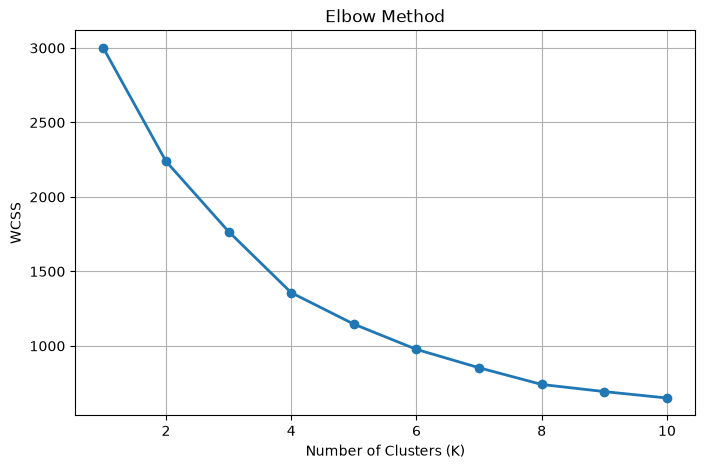

In [23]:
# ==========================================
# Plot Elbow Curve
# ==========================================

plt.figure(figsize=(8,5))

plt.plot(
    range(1,11),
    wcss,
    marker="o",
    linewidth=2
)

plt.title("Elbow Method")

plt.xlabel("Number of Clusters (K)")

plt.ylabel("WCSS")

plt.grid(True)

plt.savefig("../reports/elbow_method.png", dpi=300, bbox_inches="tight")

plt.show()

## K-Means Clustering

In [24]:
# ==========================================
# Apply K-Means Clustering
# ==========================================

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(scaled_features)

df["Cluster"] = clusters

print("K-Means Clustering Applied Successfully")

K-Means Clustering Applied Successfully


In [25]:
# ==========================================
# Cluster Count
# ==========================================

df["Cluster"].value_counts().sort_index()

Cluster
0    247
1    271
2    255
3    227
Name: count, dtype: int64

## PCA Visualization

In [26]:
# ==========================================
# PCA (2 Components)
# ==========================================

pca = PCA(n_components=2)

pca_features = pca.fit_transform(scaled_features)

pca_df = pd.DataFrame(
    pca_features,
    columns=["PC1", "PC2"]
)

pca_df["Cluster"] = clusters

pca_df.head()

,PC1,PC2,Cluster
0,-0.798924,-2.078094,1
1,0.374564,0.398385,0
2,-0.042042,-0.725342,1
3,-1.641970,-1.849602,3
4,2.329299,-0.516871,1


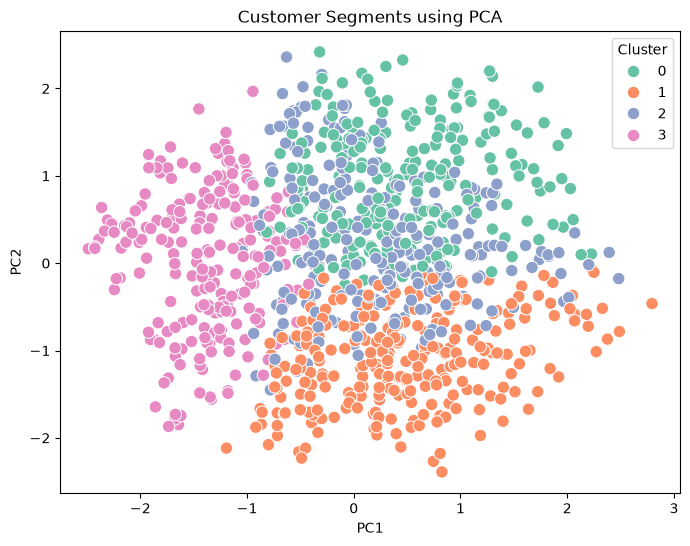

In [27]:
# ==========================================
# PCA Cluster Visualization
# ==========================================

plt.figure(figsize=(8,6))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="Set2",
    s=80
)

plt.title("Customer Segments using PCA")
plt.savefig("../reports/pca_clusters.png", dpi=300, bbox_inches="tight")

plt.show()

## Cluster Profiling

In [28]:
# ==========================================
# Cluster Profile
# ==========================================

cluster_profile = df.groupby("Cluster")[["price", "units_sold", "rating"]].mean()

cluster_profile

,price,units_sold,rating
Cluster,,,
0,1087.301012,383.161943,2.504858
1,1044.458598,127.357934,3.647970
2,486.423216,182.494118,1.872941
3,367.274802,329.607930,3.953744


In [29]:
# ==========================================
# Cluster Size
# ==========================================

df["Cluster"].value_counts().sort_index()

Cluster
0    247
1    271
2    255
3    227
Name: count, dtype: int64

## Business Recommendations

### Cluster 0
- High-value customer segment.
- Focus on premium product promotions.

### Cluster 1
- Price-sensitive customers.
- Offer discounts and seasonal sales.

### Cluster 2
- Average customers.
- Recommend personalized products.

### Cluster 3
- Highly engaged customers.
- Improve customer loyalty through reward programs.

## Basic Predictive Model (Linear Regression)

In [30]:
# ==========================================
# Define Features and Target Variable
# ==========================================

X = df[["units_sold", "rating", "product_id"]]

y = df["price"]

print("Features Shape :", X.shape)
print("Target Shape :", y.shape)

Features Shape : (1000, 3)
Target Shape : (1000,)


In [31]:
# ==========================================
# Split Dataset
# ==========================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Data :", X_train.shape)
print("Testing Data :", X_test.shape)

Training Data : (800, 3)
Testing Data : (200, 3)


In [32]:
# ==========================================
# Train Linear Regression Model
# ==========================================

model = LinearRegression()

model.fit(X_train, y_train)

print("Model Training Completed")

Model Training Completed


In [33]:
# ==========================================
# Prediction
# ==========================================

y_pred = model.predict(X_test)

print("Prediction Completed")

Prediction Completed


## Model Evaluation

In [34]:
# ==========================================
# R² Score
# ==========================================

r2 = r2_score(y_test, y_pred)

print(f"R² Score : {r2:.4f}")

R² Score : -0.0061


In [35]:
# ==========================================
# Mean Absolute Error
# ==========================================

mae = mean_absolute_error(y_test, y_pred)

print(f"MAE : {mae:.2f}")

MAE : 373.73


In [36]:
# ==========================================
# Root Mean Squared Error
# ==========================================

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"RMSE : {rmse:.2f}")

RMSE : 433.81


## Top 3 Important Features

In [37]:
# ==========================================
# Feature Importance
# ==========================================

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

feature_importance = feature_importance.sort_values(
    by="Coefficient",
    key=abs,
    ascending=False
)

display(feature_importance)

,Feature,Coefficient
1,rating,-14.205974
0,units_sold,-0.092810
2,product_id,-0.039493


In [38]:
# ==========================================
# Top 3 Features
# ==========================================

print(feature_importance.head(3))

      Feature  Coefficient
1      rating   -14.205974
0  units_sold    -0.092810
2  product_id    -0.039493


## Actual vs Predicted Prices

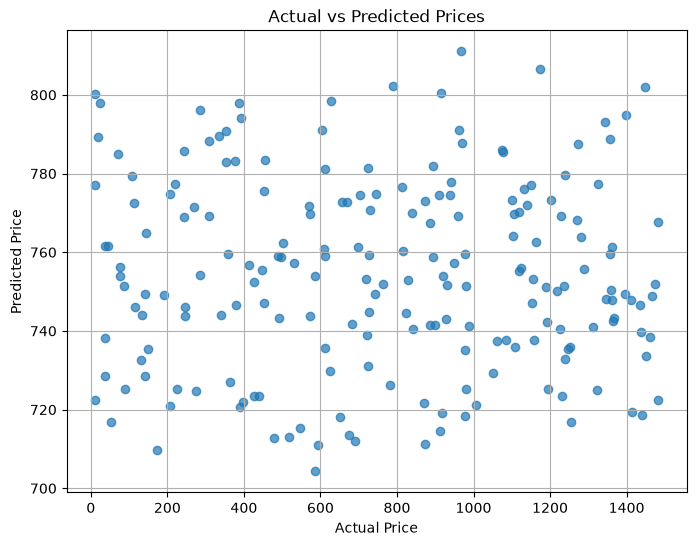

In [39]:
# ==========================================
# Actual vs Predicted
# ==========================================

plt.figure(figsize=(8,6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.7
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")

plt.title("Actual vs Predicted Prices")

plt.grid(True)
plt.savefig("../reports/actual_vs_predicted.png", dpi=300, bbox_inches="tight")

plt.show()